# Movie Night for Two

An AI lab project on recommending movies for two viewers. This notebook walks from the first genre model through the final Hybrid + rating prior ranking, with a runnable model example, charts for the public experiments, and reproduction commands.

**Main result.** Collaborative ratings improved genre-only ranking. A smoothed community-rating adjustment improved Hybrid again, but community rating alone won the shared-film benchmark. The result addresses which already-rated candidates were ranked higher.

**How to run.** Open this notebook from the repository root in a Python 3.10+ kernel with Matplotlib and IPython. The charts use saved benchmark values and the worked example uses fictional inputs, so the main notebook can run without downloading MovieLens. The reproduction commands at the end rerun the actual experiments when the public data is available.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from recommend import Movie, group_score, recommend
from hybrid import HybridModel, community_rating_prior

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.titleweight": "bold", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.axisbelow": True})
BLUE, ORANGE, TEAL, GRAY = "#245484", "#af4b0a", "#147d68", "#64748b"
SEED_COLORS = (BLUE, ORANGE, TEAL)


def compare_bars(title, methods, values, *, ylabel="Both viewers rated the pick 4+",
                 limits=(0, 66), percent=True):
    fig, ax = plt.subplots(figsize=(10, 1.6 + 0.68 * len(methods)), layout="constrained")
    seeds = tuple(values)
    width = 0.74 / len(seeds)
    for index, seed in enumerate(seeds):
        positions = [row + (index - (len(seeds) - 1) / 2) * width for row in range(len(methods))]
        bars = ax.barh(positions, values[seed], width * .88, color=SEED_COLORS[index], label=f"Seed {seed}")
        labels = [f"{value:.1f}%" if percent else f"{value:.3f}" for value in values[seed]]
        ax.bar_label(bars, labels=labels, padding=3, fontsize=8)
    ax.set(yticks=range(len(methods)), yticklabels=methods, xlabel=ylabel,
           xlim=limits, title=title)
    ax.invert_yaxis()
    if percent:
        ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.legend(loc="lower center", bbox_to_anchor=(.5, 1.13), ncols=len(seeds), frameon=False)
    plt.show()

## 1. From one viewer’s ratings to a shared pick

Every viewer profile is a dictionary of MovieLens movie IDs and star ratings. `recommend.predict` compares the genre sets of a candidate and the films already rated. It weights deviations from 3 stars by cosine similarity and includes an extra neutral vote.

`hybrid.HybridModel` adds adjusted cosine similarity from a separate set of training users. It centers each user's ratings, requires three shared raters, and shrinks relationships with low support. The genre estimate is the fallback. `community_rating_prior` shrinks a film's mean toward the overall training mean and takes half the resulting deviation as a ranking adjustment.

The group rule is `(1 − balance) × average + balance × lower prediction`. The rating prior changes the ranking score. The two personal predictions remain on their original star scale.

In [2]:
# Fictional films and ratings for a reproducible walk through the actual model code.
catalog = {
    1: Movie("Star Circuit", frozenset({"Sci-Fi", "Adventure"})),
    2: Movie("Quiet Harbor", frozenset({"Drama"})),
    3: Movie("Orbital Rescue", frozenset({"Sci-Fi", "Adventure"})),
    4: Movie("Last Light", frozenset({"Sci-Fi", "Drama"})),
    5: Movie("The Ferry", frozenset({"Drama", "Adventure"})),
}
viewer_a = {1: 5.0, 2: 2.0}
viewer_b = {1: 2.0, 2: 5.0}
training = {
    10: {1: 5, 2: 2, 3: 5, 4: 4, 5: 3},
    11: {1: 4, 2: 2, 3: 5, 4: 4, 5: 2},
    12: {1: 2, 2: 5, 3: 2, 4: 4, 5: 5},
    13: {1: 1, 2: 4, 3: 2, 4: 4, 5: 5},
}

model = HybridModel(training)
counts, rating_prior = community_rating_prior(training.values())

def explain_hybrid(movie_id, profile, genre_result):
    return model.explain(movie_id, profile, genre_result, catalog)

def rank_demo(balance):
    picks = recommend(catalog, viewer_a, viewer_b, balance, adjust=explain_hybrid)
    return sorted(picks, key=lambda item: (
        -(item.score + rating_prior.get(item.movie_id, 0)), item.movie.title.casefold(), item.movie_id
    ))

for balance in (0, .5, 1):
    print(f"Balance {balance:.0%}")
    for pick in rank_demo(balance):
        adjustment = rating_prior.get(pick.movie_id, 0)
        print(f"  {pick.movie.title:<16} A {pick.first.score:.2f}  B {pick.second.score:.2f}  "
              f"prior {adjustment:+.2f}  rank {pick.score + adjustment:.2f}")

first_pick = rank_demo(.5)[0]
print()
print(f"Evidence for {first_pick.movie.title}, Viewer A")
print(first_pick.first.evidence)

Balance 0%
  Last Light       A 2.85  B 3.49  prior +0.03  rank 3.20
  The Ferry        A 2.57  B 3.78  prior +0.02  rank 3.19
  Orbital Rescue   A 4.17  B 2.15  prior +0.00  rank 3.16
Balance 50%
  Last Light       A 2.85  B 3.49  prior +0.03  rank 3.04
  The Ferry        A 2.57  B 3.78  prior +0.02  rank 2.89
  Orbital Rescue   A 4.17  B 2.15  prior +0.00  rank 2.65
Balance 100%
  Last Light       A 2.85  B 3.49  prior +0.03  rank 2.88
  The Ferry        A 2.57  B 3.78  prior +0.02  rank 2.59
  Orbital Rescue   A 4.17  B 2.15  prior +0.00  rank 2.15

Evidence for Last Light, Viewer A
Star Circuit (5/5), shared genres: Sci-Fi
MovieLens relationship with Star Circuit (5/5) lowered the rating-based estimate most.


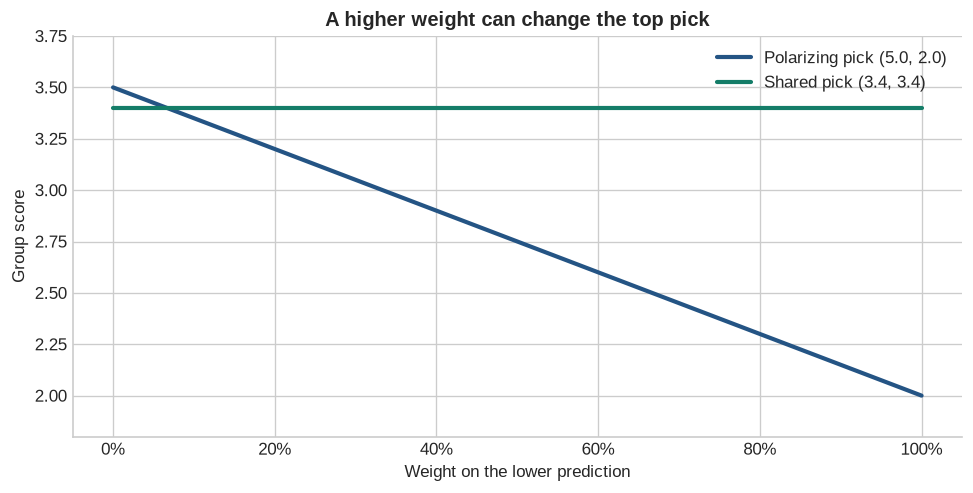

In [3]:
# Isolate the group rule with two hypothetical pairs of predictions.
weights = [index / 20 for index in range(21)]
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for label, scores, color in [("Polarizing pick (5.0, 2.0)", (5, 2), BLUE),
                             ("Shared pick (3.4, 3.4)", (3.4, 3.4), TEAL)]:
    ax.plot(weights, [group_score(*scores, weight) for weight in weights],
            label=label, linewidth=2.5, color=color)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel="Weight on the lower prediction", ylabel="Group score",
       title="A higher weight can change the top pick", ylim=(1.8, 3.75))
ax.legend()
plt.show()

## 2. Data and evaluation

| Source | Role |
| --- | --- |
| MovieLens Latest Small | First baseline, input-count experiment, and initial Hybrid benchmark |
| MovieLens 32M | Larger benchmark and final demo catalog |
| Kaggle TMDB + IMDb snapshot v1074 | Coverage audit and director, cast, and plot ablation |

Within each run, every method ranks the same 20 held-out films that both viewers rated. The prototype experiments use 300 eligible pairs. The 32M runs use 500 pairs. The hybrid benchmarks reserve test users before fitting collaborative relationships and sample training users in nested sets. The 32M comparisons use 10 known ratings per viewer.

**Joint approval** is the percentage of top-five picks that both viewers rated at least 4 stars. **Mean actual rating** averages the two actual scores over those picks. Treat the seeds as repeated splits of the same dataset. The pairs can also share viewers.

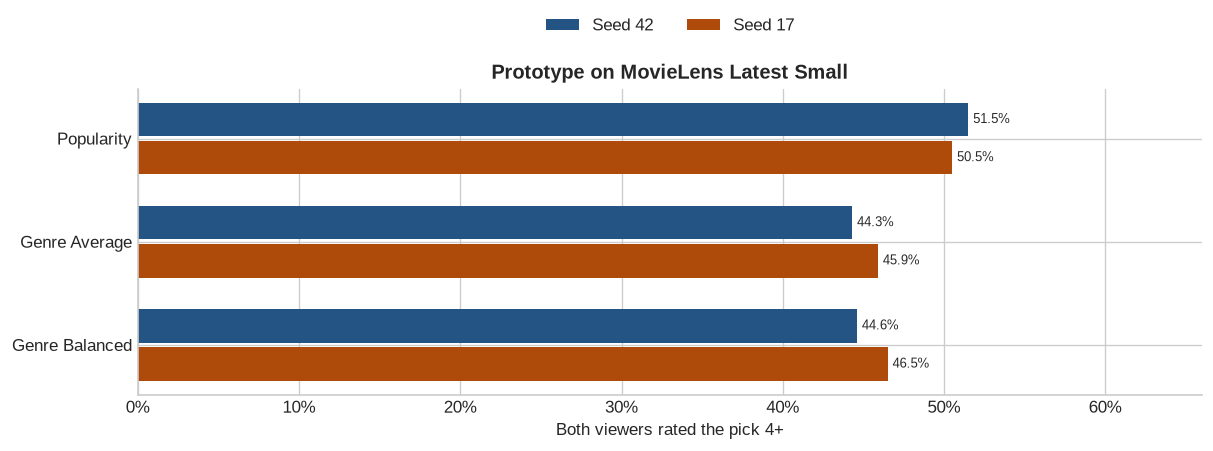

In [4]:
compare_bars("Prototype on MovieLens Latest Small",
             ["Popularity", "Genre Average", "Genre Balanced"],
             {42: [51.5, 44.3, 44.6], 17: [50.5, 45.9, 46.5]})

## 3. How many known ratings help?

The input-count experiment holds pairs and candidates fixed within each seed. Three ratings are included in five, and five are included in ten. Ten gave the best scores under both genre ranking rules on both runs. The change from three to five was mixed.

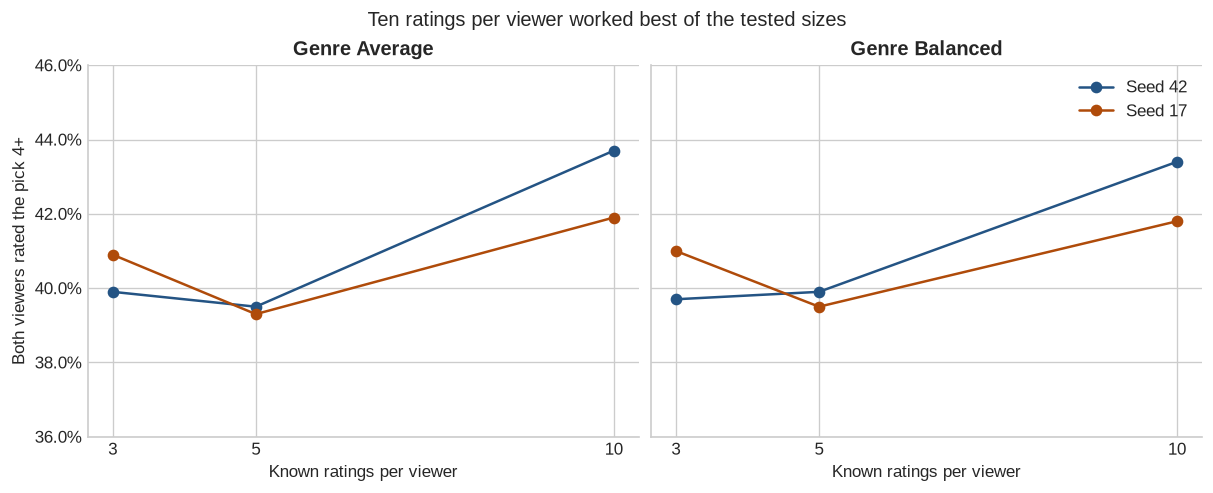

In [5]:
input_sizes = [3, 5, 10]
average = {42: [39.9, 39.5, 43.7], 17: [40.9, 39.3, 41.9]}
balanced = {42: [39.7, 39.9, 43.4], 17: [41.0, 39.5, 41.8]}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, layout="constrained")
for ax, label, series in zip(axes, ("Genre Average", "Genre Balanced"), (average, balanced)):
    for (seed, values), color in zip(series.items(), SEED_COLORS):
        ax.plot(input_sizes, values, "o-", color=color, label=f"Seed {seed}")
    ax.set(title=label, xlabel="Known ratings per viewer", xticks=input_sizes, ylim=(36, 46))
    ax.yaxis.set_major_formatter(PercentFormatter(100))
axes[0].set_ylabel("Both viewers rated the pick 4+")
axes[1].legend()
fig.suptitle("Ten ratings per viewer worked best of the tested sizes")
plt.show()

## 4. Does learning from more people help?

The small experiment grew Hybrid from 114 to 458 training users. The 32M experiment compared 5,000, 10,000, and 20,000 within the same split. Both 32M rules improved from 5,000 to 10,000 users, while gains at 20,000 were mixed. The larger benchmark caps training at 20,000 users for tractability.

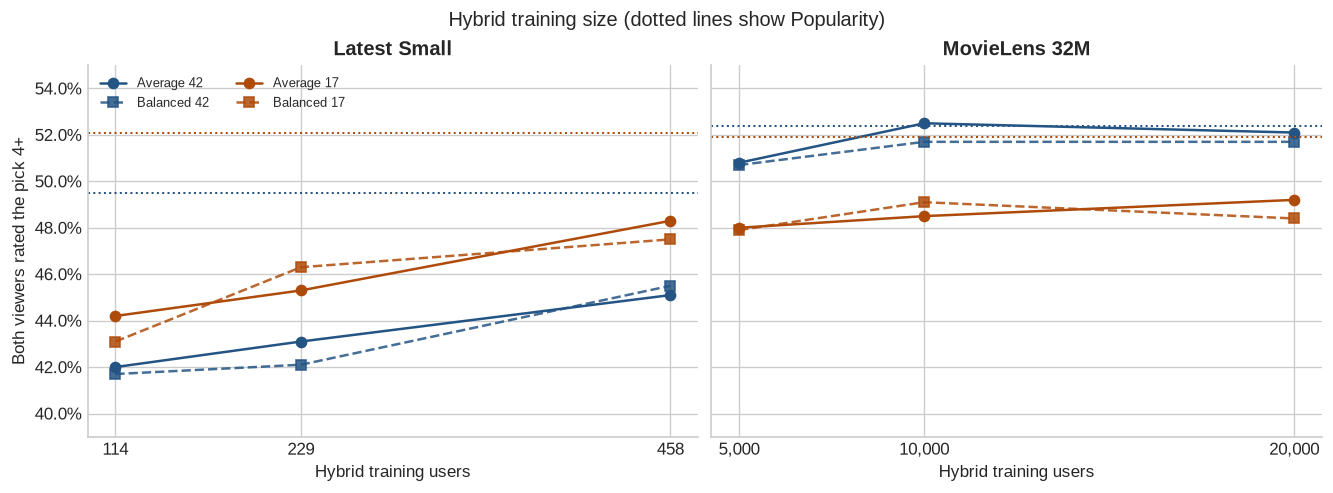

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
stages = (
    ("Latest Small", [114, 229, 458],
     {42: ([42.0, 43.1, 45.1], [41.7, 42.1, 45.5], 49.5),
      17: ([44.2, 45.3, 48.3], [43.1, 46.3, 47.5], 52.1)}),
    ("MovieLens 32M", [5000, 10000, 20000],
     {42: ([50.8, 52.5, 52.1], [50.7, 51.7, 51.7], 52.4),
      17: ([48.0, 48.5, 49.2], [47.9, 49.1, 48.4], 51.9)}),
)
for ax, (label, sizes, series) in zip(axes, stages):
    for (seed, (avg, bal, popularity)), color in zip(series.items(), SEED_COLORS):
        ax.plot(sizes, avg, "o-", color=color, label=f"Average {seed}")
        ax.plot(sizes, bal, "s--", color=color, alpha=.85, label=f"Balanced {seed}")
        ax.axhline(popularity, color=color, linestyle=":", linewidth=1.2)
    ax.set(title=label, xlabel="Hybrid training users", xticks=sizes,
           xticklabels=[f"{size:,}" for size in sizes], ylim=(39, 55))
    ax.yaxis.set_major_formatter(PercentFormatter(100))
axes[0].set_ylabel("Both viewers rated the pick 4+")
axes[0].legend(loc="upper left", fontsize=8, ncols=2)
fig.suptitle("Hybrid training size (dotted lines show Popularity)")
plt.show()

## 5. Do director, cast, and plot help?

The audit matched **98.8%** of MovieLens 32M films to the Kaggle snapshot. We tested director overlap, overlap among the first five cast members, and TF-IDF cosine similarity between plot overviews. Each feature was blended individually with genre similarity. Missing fields fell back to genres. All three additions lost a little on seed 42 and gained a little on seed 17. Coverage was high, but the experiment showed no consistent improvement. Only two pair-film observations across these runs met the sparse-film threshold.

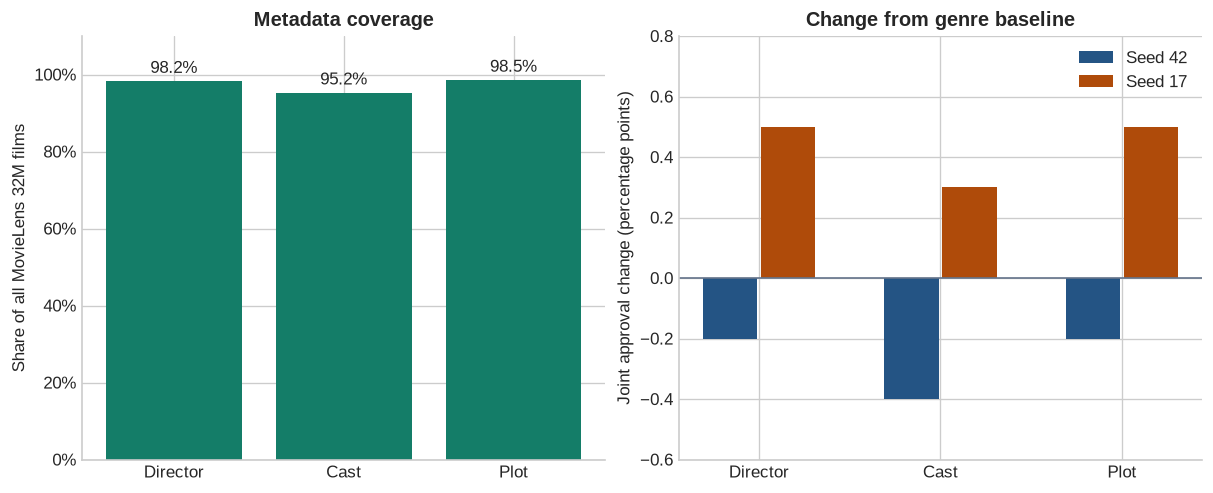

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
fields = ["Director", "Cast", "Plot"]
axes[0].bar(fields, [98.2, 95.2, 98.5], color=TEAL)
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=3)
axes[0].set(title="Metadata coverage", ylabel="Share of all MovieLens 32M films", ylim=(0, 110))
axes[0].yaxis.set_major_formatter(PercentFormatter(100))
delta = {42: [-.2, -.4, -.2], 17: [.5, .3, .5]}
for i, ((seed, values), color) in enumerate(zip(delta.items(), SEED_COLORS)):
    x = [j + (i - .5) * .32 for j in range(len(fields))]
    axes[1].bar(x, values, width=.30, color=color, label=f"Seed {seed}")
axes[1].axhline(0, color=GRAY, linewidth=1)
axes[1].set(title="Change from genre baseline", ylabel="Joint approval change (percentage points)",
            xticks=range(len(fields)), xticklabels=fields, ylim=(-.6, .8))
axes[1].legend()
plt.show()

## 6. What changed in the final model?

The final comparison fits Hybrid and estimates the adjustment using the same 10,000-user training subset. The full-training popularity baseline uses all non-test users. Hybrid + rating prior improves on plain Hybrid and Popularity on all three splits. Community rating alone leads on both metrics. Balanced plus the prior scores slightly below Average plus the prior on joint approval in these runs.

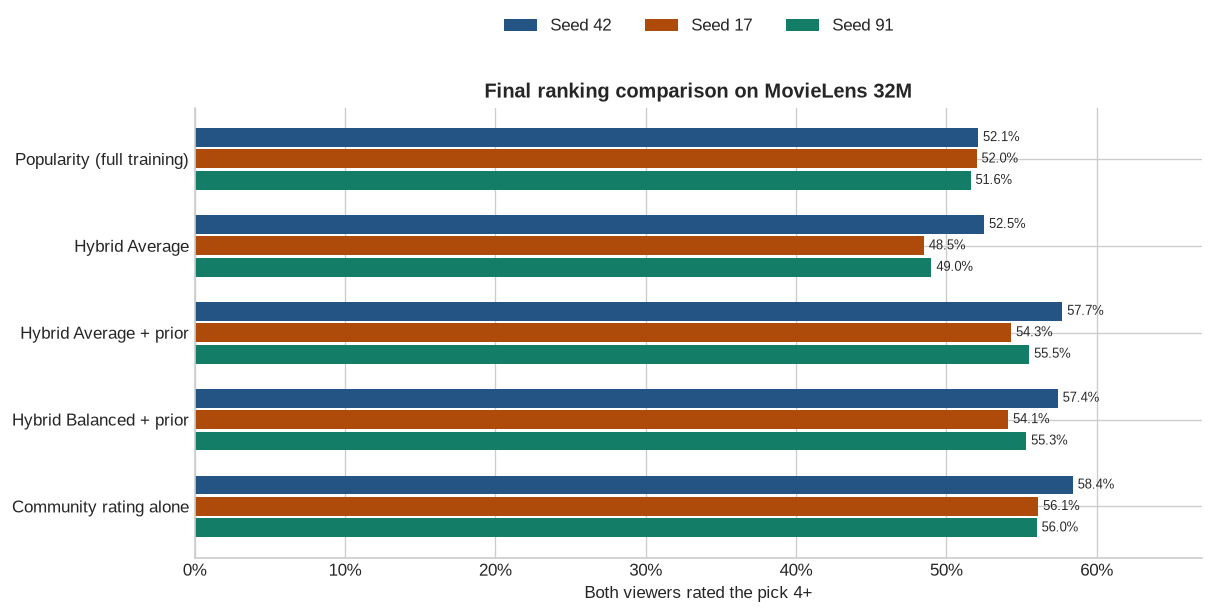

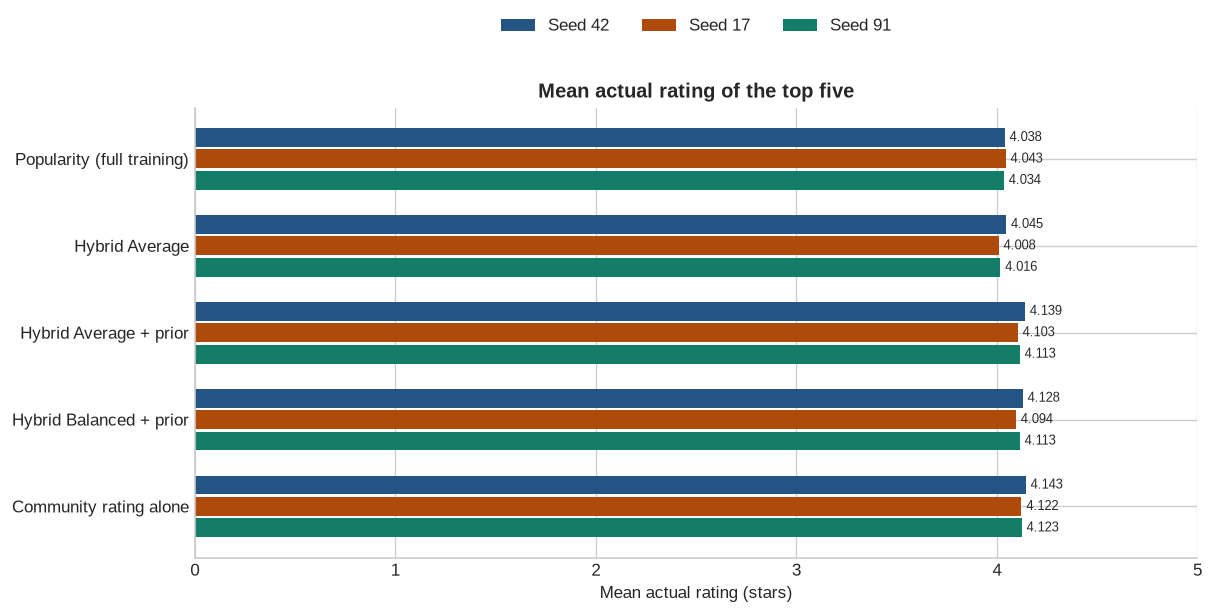

In [8]:
methods = ["Popularity (full training)", "Hybrid Average", "Hybrid Average + prior",
           "Hybrid Balanced + prior", "Community rating alone"]
joint = {42: [52.1, 52.5, 57.7, 57.4, 58.4],
         17: [52.0, 48.5, 54.3, 54.1, 56.1],
         91: [51.6, 49.0, 55.5, 55.3, 56.0]}
mean = {42: [4.038, 4.045, 4.139, 4.128, 4.143],
        17: [4.043, 4.008, 4.103, 4.094, 4.122],
        91: [4.034, 4.016, 4.113, 4.113, 4.123]}
compare_bars("Final ranking comparison on MovieLens 32M", methods, joint, limits=(0, 67))
compare_bars("Mean actual rating of the top five", methods, mean,
             ylabel="Mean actual rating (stars)", limits=(0, 5), percent=False)

## 7. Run the demo and reproduce the experiments

| File | Responsibility |
| --- | --- |
| `recommend.py` | Catalog reader, genre predictions, group score, and command-line entry point |
| `hybrid.py` | Centered item similarity, prediction evidence, and community prior |
| `app.py` | Viewer profiles, fictional presets, model and balance controls, and ranked cards |
| `prepare_demo.py` | Recreates the 10,000-user seed-42 demo sample from the 32M archive |
| `evaluate.py` | Popularity and genre baselines, plus input-count comparisons |
| `evaluate_hybrid.py` | Nested training sizes and final rating-prior comparisons |
| `audit_metadata.py` and `evaluate_metadata.py` | ID matching, metadata coverage, and individual feature comparisons |

Run these commands in a terminal from the repository root. Place the [public GroupLens archives](https://grouplens.org/datasets/movielens/) and the [Kaggle snapshot](https://www.kaggle.com/datasets/alanvourch/tmdb-movies-daily-updates/versions/1074) under `data/` as described in the [README](README.md).

```bash
python -m pip install -r requirements.txt
python prepare_demo.py
MOVIE_RECOMMEND_DATA=data/ml-32m-demo.zip python -m streamlit run app.py
```

```bash
python evaluate.py
python evaluate.py --profile-sizes 3 5 10
python evaluate_hybrid.py
python audit_metadata.py --movielens data/ml-32m.zip --metadata data/tmdb-movies-daily-updates.zip
python evaluate_metadata.py
python evaluate_hybrid.py --data-dir data/ml-32m.zip --training-users 20000 --pairs 500
python evaluate_hybrid.py --data-dir data/ml-32m.zip --training-users 20000 --pairs 500 --compare-priors
```

Use `--seed 17` for the second run of each rating experiment and `--seed 91` for the third rating-prior run. The population-size and prior benchmarks stream the larger archive and take longer than the small evaluations.

### Present it live

Load **Toy Story vs. Jumanji** and switch from **Genre** to plain **Hybrid**. With Hybrid selected, show that Balanced matches Average at **0%**, then move to **50%**. Load **Horror vs. animation** to illustrate the slider on opposing preferences. Expand **Why this pick?** to trace a personal score. Switch back to **Hybrid + rating prior** to show the current default.

### Interpret the result

The benchmark measures reranking on films both viewers had already rated. Highly visible films can be overrepresented in that pool. The demo ranks the full catalog, where the model can encounter new or rarely rated films. The experiments establish an improvement over the genre baseline and plain Hybrid on the tested candidate lists. A prospective test in which both viewers watch and rate unfamiliar recommendations would address discovery.